# Notatnik trenujący macierz interakcji pomiędzy grupami obiektów

Projekt dyplomowy - Łukasz Jugo 331700

Niniejszy notatnik jest elementem projektu dyplomowego "Zastosowanie modeli wizualno-językowych do przetwarzania sekwencji wideo nagrań ruchu drogowego". Skupia się on na generowaniu macierzy interakcji pomiędzy obiektami klas należących do dwóch grup: pojazdów i osób oraz jej wizualizacji za pomocą map ciepła. Do działania oprócz nagrania potrzebny jest plik json z detekcjami wygenerowany przez skrypt `video_to_json.py`. Przy tworzeniu notatnika korzystałem z Pythona w wersji 3.14.5.

**Wczytanie bibliotek**

In [1]:
import json
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

**Ścieżki do plików**

W tej części musimy zdefiniować ścieżki do odpowiednich plików, które będą używane w dalszej części notatnika. Są to odpowiednio:
- `json_path` - ścieżka do pliku JSON z detekcjami,
- `video_path` - ścieżka do pliku wideo,
- `output_path` - ścieżka w której zostanie zapisane wynikowa macierz.

In [2]:
json_path = "film2.json"
video_path = "film2.mp4"
output_path = "interactionMatrix.npy"

**Wczytanie danych z jsona**

In [3]:
with open(json_path, "r", encoding="utf-8") as input:
    tracks_data = json.load(input)
print(f"Liczba obiektów: {len(tracks_data)}\n")
records = []

for track_id_str, detections in tracks_data.items():
    for det in detections:
        records.append({
            "track_id": int(track_id_str),
            "class_id": det["class_id"],
            "class_name": det["class_name"],
            "confidence": round(det["confidence"], 3),
            "x": round(det["bbox"][0], 1),
            "y": round(det["bbox"][1], 1),
            "w": round(det["bbox"][2], 1),
            "h": round(det["bbox"][3], 1)
        })

df_tracks = pd.DataFrame(records)
df_tracks.head()

Liczba obiektów: 4595



,track_id,class_id,class_name,confidence,x,y,w,h
0,19,2,car,0.526,690.6,389.5,56.0,177.8
1,19,2,car,0.752,691.7,385.6,52.4,180.7
2,19,2,car,0.536,692.3,376.1,52.4,182.1
3,19,2,car,0.690,692.7,368.1,50.4,177.3
4,19,2,car,0.584,693.3,358.9,49.4,172.1


**Obliczanie przesunięć**

Aby określić czy dany obiekt porusza się czy też nie dla każdej detekcji o unikalnym track_id obliczamy jej przesunięcie według następującego algorytmu:
- dla pierwszych 30 detekcji danego obiektu przesunięcie wynosi 0,
- każde następne przesunięcie obliczane jest ze wzoru\\ $d=\sqrt{(x_{aktualne} - x_{30klatekwczesniej})^2 + (y_{aktualne} - y_{30klatekwczesniej})^2}$.

Na końcu wyświetlamy zmodyfikowanego dataframe.

In [4]:
N_FRAMES = 30

df_tracks['x_past'] = df_tracks.groupby('track_id')['x'].shift(N_FRAMES)
df_tracks['y_past'] = df_tracks.groupby('track_id')['y'].shift(N_FRAMES)

euclidean_distance = np.sqrt(
    (df_tracks['x'] - df_tracks['x_past'])**2 + 
    (df_tracks['y'] - df_tracks['y_past'])**2
)

df_tracks['przesunięcie'] = euclidean_distance.fillna(0.0)
df_tracks['przesunięcie'] = df_tracks['przesunięcie'].round(2)
df_tracks = df_tracks.drop(columns=['x_past', 'y_past'])
df_tracks.head(35)

,track_id,class_id,class_name,confidence,x,y,w,h,przesunięcie
0,19,2,car,0.526,690.6,389.5,56.0,177.8,0.00
1,19,2,car,0.752,691.7,385.6,52.4,180.7,0.00
2,19,2,car,0.536,692.3,376.1,52.4,182.1,0.00
3,19,2,car,0.690,692.7,368.1,50.4,177.3,0.00
4,19,2,car,0.584,693.3,358.9,49.4,172.1,0.00
5,19,2,car,0.629,693.5,350.2,48.5,167.9,0.00
6,19,2,car,0.450,693.7,341.3,47.2,163.9,0.00
7,19,2,car,0.641,693.7,333.0,46.5,159.7,0.00
8,19,2,car,0.881,693.5,324.7,46.4,156.6,0.00
9,19,2,car,0.860,693.2,316.7,46.9,153.7,0.00


**Filtracja danych - elementy stojące i poruszające się**

Klasyfikowanie obiektów jako obiekty w ruchu i bezruchu odbywa się na podstawie średniego przesunięcia, z góry określonego dla danej klasy. Jeśli średnie przesunięcie dla danej detekcji jest co najmniej równe progowi wtedy uznajemy, że dany obiekt porusza się. Jeśli jest to wartość mniejsza niż próg wtedy jest to obiekt stojący. Na koniec wyświetlamy 50 pierwszych detekcji wraz z ich klasyfikacją.

In [5]:
PROGI_KLAS = {
    'car': 50.0,
    'truck': 50.0,
    'bus': 50.0,
    'motorcycle': 50.0,
    'person': 10.0,
    'umbrella': 10.0
}

srednie_przesunięcia = df_tracks.groupby('track_id').agg(
    srednie_przesunięcie=('przesunięcie', 'mean'),
    class_name=('class_name', 'first')
).reset_index()

srednie_przesunięcia['wymagany_prog'] = srednie_przesunięcia['class_name'].map(PROGI_KLAS)

ruch_df = srednie_przesunięcia[srednie_przesunięcia['srednie_przesunięcie'] >= srednie_przesunięcia['wymagany_prog']]
bezruch_df = srednie_przesunięcia[srednie_przesunięcia['srednie_przesunięcie'] < srednie_przesunięcia['wymagany_prog']]

ruch = ruch_df['track_id'].tolist()
bezruch = bezruch_df['track_id'].tolist()

print(f"Liczba obiektów ruszających się: {len(ruch)}")
print(f"Liczba obiektów nieruszających się: {len(ruch)}")
print(f"Lista 20 pierwszych ID ruszających się obiektów: {ruch[:20]}")
print(f"Lista 20 pierwszych ID nieruszających się obiektów: {bezruch[:20]}\n")

df_wyniki = srednie_przesunięcia.copy()
df_wyniki['srednie_przesunięcie'] = df_wyniki['srednie_przesunięcie'].round(2)
df_wyniki['zakwalifikowany'] = df_wyniki['srednie_przesunięcie'] > df_wyniki['wymagany_prog']
df_wyniki = df_wyniki.sort_values(by='track_id', ascending=True).reset_index(drop=True)
df_wyniki.head(50)

Liczba obiektów ruszających się: 1012
Liczba obiektów nieruszających się: 1012
Lista 20 pierwszych ID ruszających się obiektów: [260, 275, 277, 297, 306, 503, 645, 702, 752, 786, 867, 924, 945, 1024, 1077, 1131, 1223, 1253, 1386, 1414]
Lista 20 pierwszych ID nieruszających się obiektów: [19, 37, 56, 171, 226, 241, 259, 269, 280, 287, 307, 355, 369, 388, 431, 434, 435, 440, 452, 464]



,track_id,srednie_przesunięcie,class_name,wymagany_prog,zakwalifikowany
0,19,43.19,car,50.0,False
1,37,1.57,car,50.0,False
2,56,0.00,car,50.0,False
3,171,0.00,car,50.0,False
4,226,0.00,car,50.0,False
5,241,0.00,car,50.0,False
6,259,0.00,person,10.0,False
7,260,61.26,car,50.0,True
8,269,1.34,car,50.0,False
9,275,90.66,person,10.0,True


In [6]:
ruch_detections = df_tracks[df_tracks['track_id'].isin(ruch)]
bezruch_detections = df_tracks[df_tracks['track_id'].isin(bezruch)]

**Funkcje do treningu i generacji heatmap**

Poniższe funkcje `generateHeatmap` i `trainMatrix` służą odpowiednio do wizualizacji macierzy częstości występowania oraz tworzenia samej macierzy na podstawie utworzonego wcześniej dataframe i nagrania wideo służącego jako podkład do wizualizacji i źródło wymiarów do macierzy. Aby zapobiec gromadzeniu się detekcji na krawędziach macierzy (efekt ten jest spowodowany perspektywą i stopniowym zmniejszaniem się wielkości ramki przez co ich gęstość występowania na krawędziach jest większa niż winikałoby to tylko z obecności obiektu w tym miejscu) wprowadzono martwą strefę o szerokości 10 pikseli od krawędzi. Jeśli ramka się w niej znajdzie jakąkolwiek współrzędną nie jest brana pod uwagę. Następnie w miejscu gdzie znajduje się centroid ramki dodajemy 1.0 do macierzy oraz 0.4 w każdym miejscu ramki. Potem całość przechodzi przez filtr Gaussa tak, aby rozmyć różnice pomiędzy elementami macierzy

In [7]:
def generateHeatmap(first_frame, matrix, caption):
    height = first_frame.shape[0]
    width = first_frame.shape[1]
    fig, ax = plt.subplots(figsize=(12, 12 * (height / width)))
    ax.axis("off")
    
    ax.imshow(first_frame)
    ax.imshow(matrix, cmap="jet", alpha=0.5, vmin=0, vmax=1)
    
    ax.set_title(caption, fontsize=14, pad=10)
    
    plt.tight_layout()
    plt.show()

In [8]:
def trainMatrix(first_frame, sigma, detections, caption, heatmap):
    height = first_frame.shape[0]
    width = first_frame.shape[1]
    density = np.zeros((height, width), dtype=np.float32)

    for _, row in detections.iterrows():
        w = int(row['w'])
        h = int(row['h'])
        x1 = int(row['x'] - w/2)
        x2 = int(row['x'] + w/2)
        y1 = int(row['y'] - h/2)
        y2 = int(row['y'] + h/2)
        cx = int(row['x'])
        cy = int(row['y'])
        
        #sprawdzamy czy ramka jest co najmniej piksel od krawedzi obrazu
        if (10 <= x1 < width-10) and (10 <= y1 < height-10) and (10 <= x2 < width-10) and (10 <= y2 < height-10):
            density[cy, cx] += 1.0
            density[y1:y2, x1:x2] += 0.4

    smoothed = gaussian_filter(density, sigma=sigma)
    max_val = smoothed.max()
    if max_val > 0:
        smoothed /= max_val

    if heatmap:
        generateHeatmap(first_frame, smoothed, f"{caption} | Uwzględnione detekcje: {len(detections)}")
    
    return smoothed

**Wczytanie pierwszej klatki nagrania potrzebnej do wizualizacji**

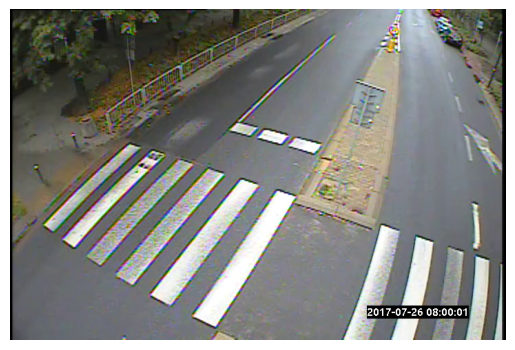

In [9]:
cap = cv2.VideoCapture(video_path)
ret, first_frame = cap.read()
if(not ret):
    print("Nie można odczytać pierwszej klatki z wideo.")
    exit(1)
plt.axis('off')
plt.imshow(cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB))

**Parametry wczytanego nagrania**

In [10]:
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration_seconds = frame_count / fps / 60

print(f"Rozdzielczość: {width}x{height} pikseli")
print(f"Klatki na sekundę (FPS): {fps}")
print(f"Całkowita liczba klatek: {frame_count}")
print(f"Długość nagrania: {duration_seconds:.2f} minut")

cap.release()

Rozdzielczość: 720x480 pikseli
Klatki na sekundę (FPS): 29.97000006838848
Całkowita liczba klatek: 107805
Długość nagrania: 59.95 minut


**Heatmapy dla obiektów poruszających się**

W tej części generowane są mapy ciepła dla obiektów poruszających się z klas zdefiniowanych przez YOLO: car oraz person. Promień rozmycia sigma jest ustawiony na 40

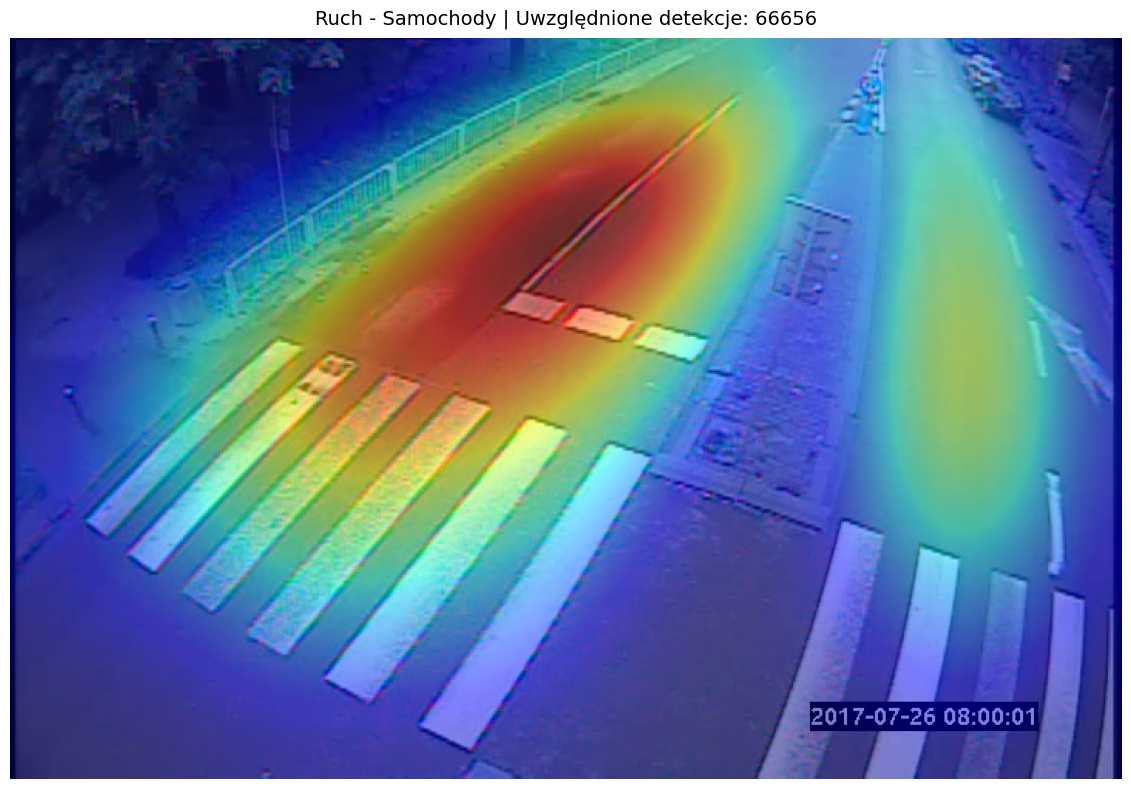

In [11]:
det = ruch_detections[ruch_detections['class_name'] == 'car']
_ = trainMatrix(first_frame, 40.0, det, "Ruch - Samochody", True)

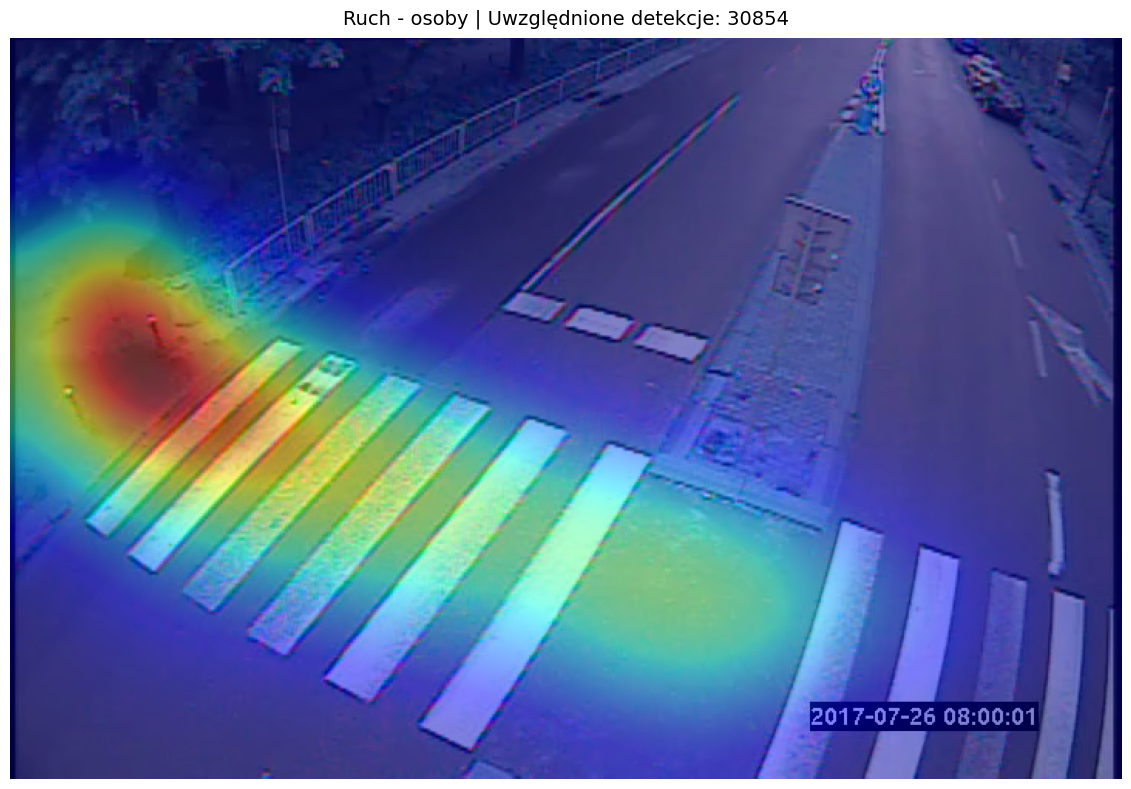

In [12]:
det = ruch_detections[ruch_detections['class_name'] == 'person']
_ = trainMatrix(first_frame, 40.0, det, "Ruch - osoby", True)

**Heatmapy obiektów nie poruszających się**

W tej części generowane są mapy ciepła dla obiektów nie poruszających się z klas zdefiniowanych przez YOLO: car oraz person. Promień rozmycia sigma jest ustawiony na 40.

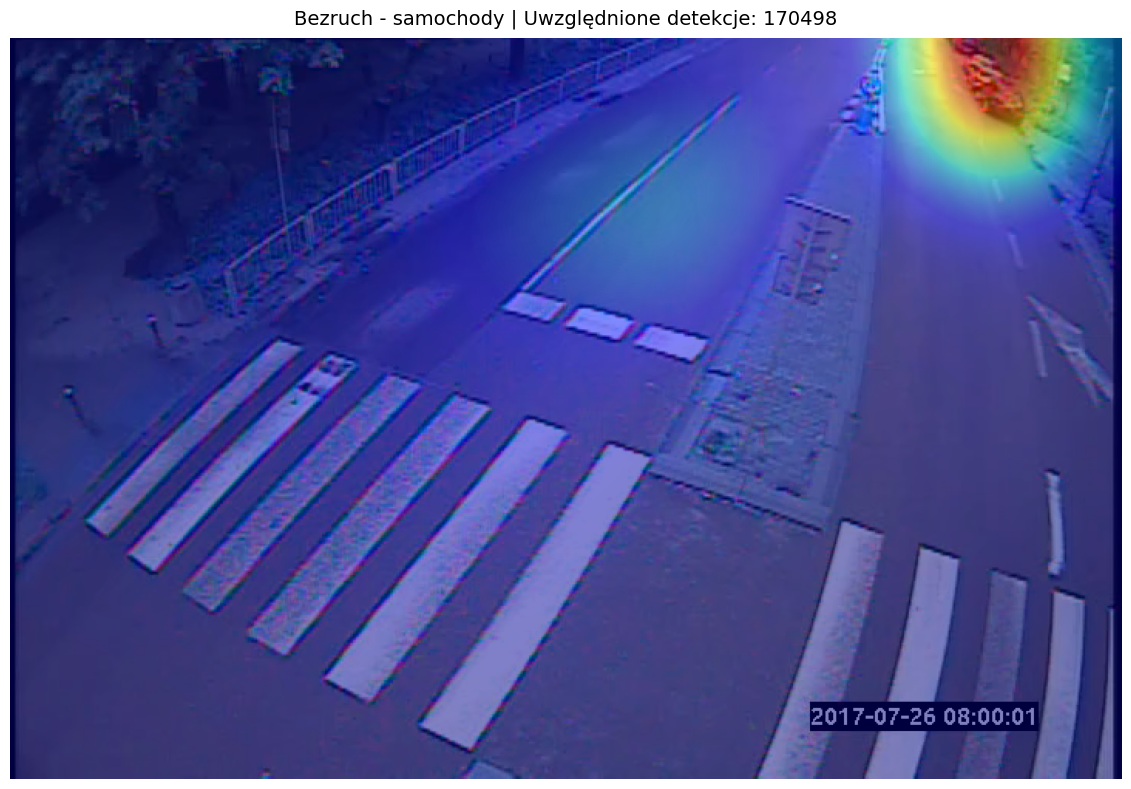

In [13]:
det = bezruch_detections[bezruch_detections['class_name'] == 'car']
_ = trainMatrix(first_frame, 40.0, det, "Bezruch - samochody", True)

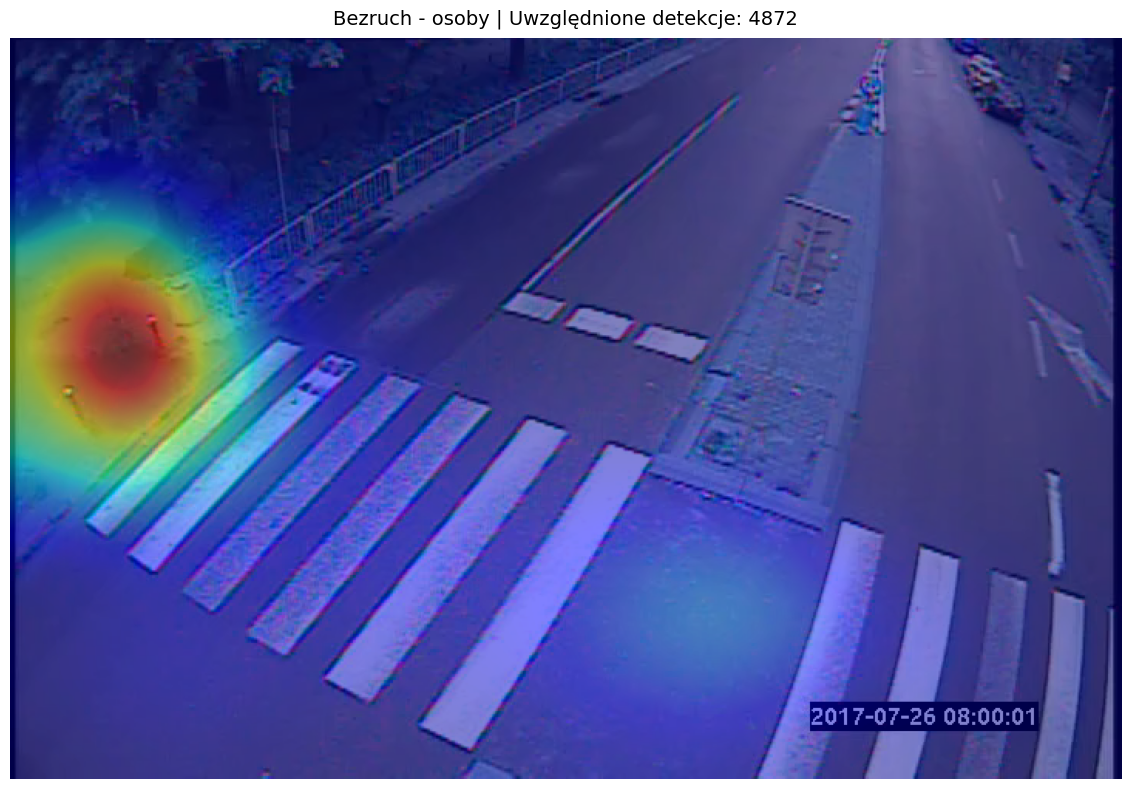

In [14]:
det = bezruch_detections[bezruch_detections['class_name'] == 'person']
_ = trainMatrix(first_frame, 40.0, det, "Bezruch - osoby", True)

**Generacja heatmap poruszających się obiektów w dwóch grupach: pojazdy, osoby**

Aby uwzględnić różnorodność klas w YOLO przydzielam klasy odpowiadające za pojazdy i osoby do dwóch grup: group1 (pojazdy) i group2 (osoby). Dzięki temu jeśli YOLO wykryje np. ciężarówkę a nie samochód to nadal ta detekcja zostanie uwzględniona jako pojazd. To samo tyczy się osób z parasolkami przez które często właściwa osoba jest zasłonięta. Na podstawie tego podziału tworzone są dwa dataframe i generowane dwie macierze częstości.

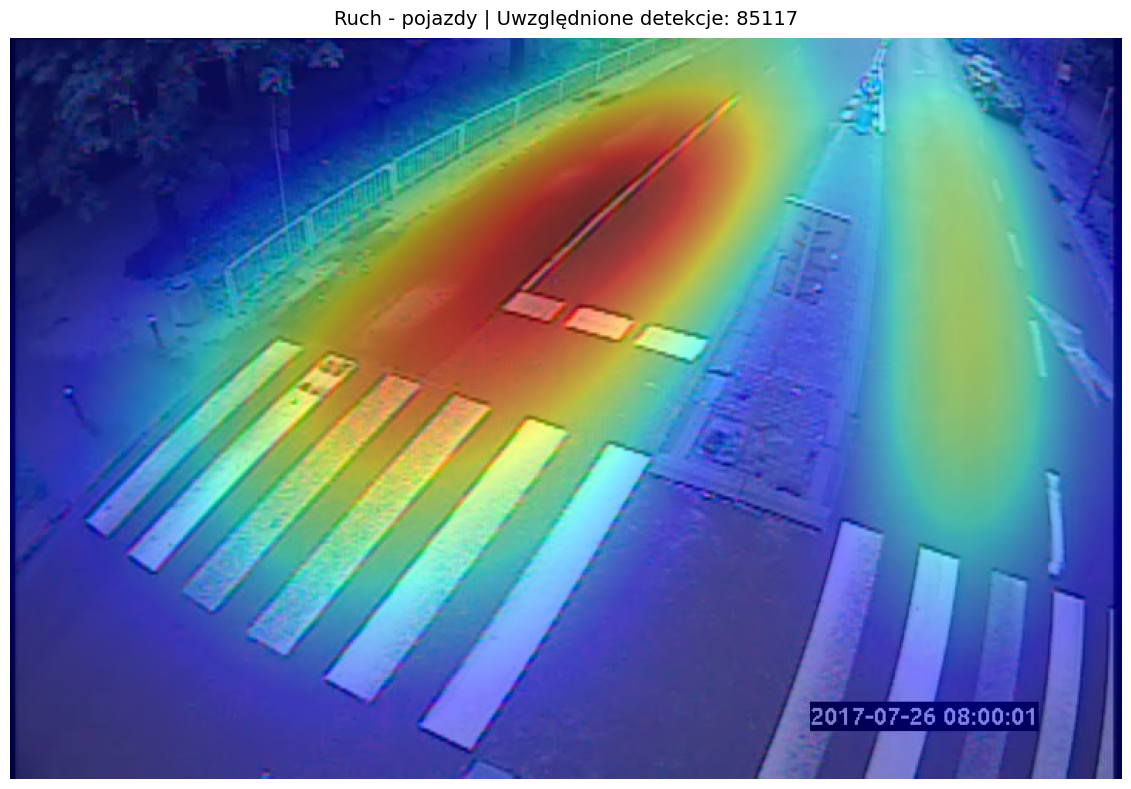

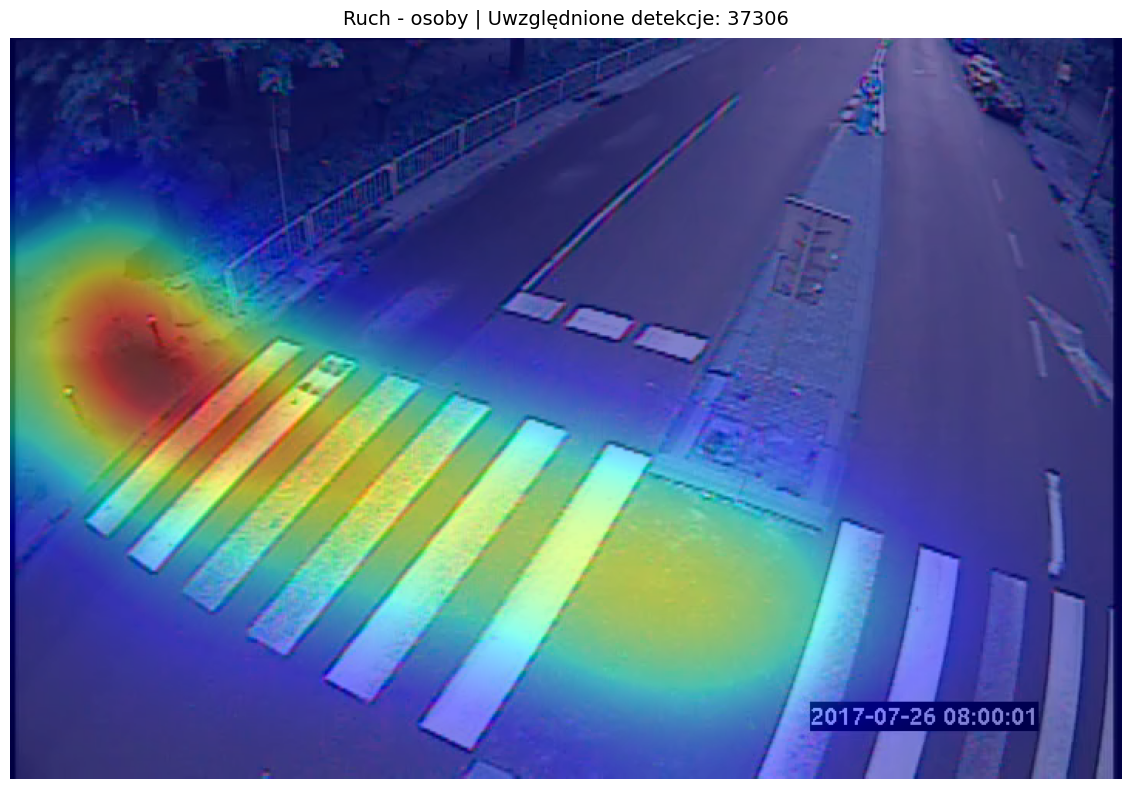

In [15]:
group1 = ['car', 'truck', 'bus', 'motorcycle']
group2 = ['person', 'umbrella']

det1 = ruch_detections[ruch_detections['class_name'].isin(group1)]
det2 = ruch_detections[ruch_detections['class_name'].isin(group2)]

matrix1 = trainMatrix(first_frame, 40.0, det1, "Ruch - pojazdy", True)
matrix2 = trainMatrix(first_frame, 40.0, det2, "Ruch - osoby", True)

**Generacja macierzy interakcji - metodą mnożenia**

Następnie w celu wyznaczenia obszaru interkacji obiektów z obu grup generujemy macierz interkacji mnożąc każdy element macierzy dla grupy 1 z odpowiadającym mu elementem z macierzy dla grupy 2. Całość jest normalizowana do przedziału [0,1] i wizualizowana

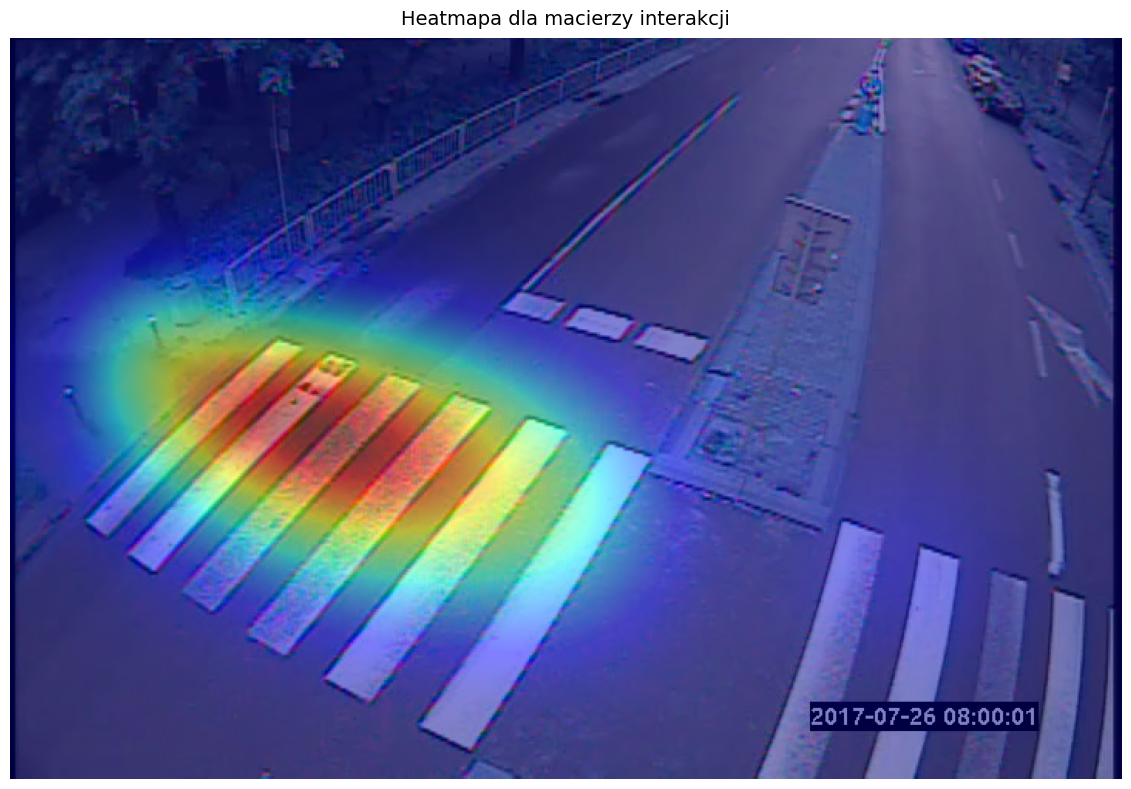

In [16]:
resultMatrix = matrix1 * matrix2
resultMatrix = resultMatrix / np.ndarray.max(resultMatrix)
generateHeatmap(first_frame, resultMatrix, "Heatmapa dla macierzy interakcji")

**Zapisanie macierzy interakcji do pliku w celu dalszego wykorzystania w kodzie przycinającym sekwencje nagrań**

In [17]:
np.save(output_path, resultMatrix)